# What makes a movie popular? Genre, recency or rating?

*Enhanced version of my original notebook, `Movie Data Analysis - Netflix (1).ipynb`, which is kept unchanged in this repo.*

**Research question.** In this dataset of ~9,800 popular films, is a film's popularity explained mainly by its **genre**, by **how recently it was released**, or by **how well audiences rate it**?

**Data.** `mymoviedb.csv`: popular films with TMDB popularity scores, vote counts, average ratings, release dates and genres. It is widely shared on Kaggle as a "Netflix" dataset, but the poster links all point to The Movie Database (TMDB), so it describes popular films in general rather than Netflix's catalogue.

**Popularity** is TMDB's own score, driven by recent page views, votes and watch-list activity, so it measures *current attention*, not quality or box office.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

BG, FG, MUTED, A1, A2, A3 = '#0F0E17', '#F4F1EA', '#9A93A8', '#E8577C', '#E8B86D', '#6D5EF5'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'axes.edgecolor':'#3a3747','axes.labelcolor':MUTED,
  'xtick.color':MUTED,'ytick.color':MUTED,'text.color':FG,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
  'axes.grid':True,'axes.axisbelow':True,'grid.color':'#24222f','savefig.facecolor':BG,'savefig.dpi':160})

## 1. Load and clean, fixing four issues from the original

| Issue in the original | Fix here |
|---|---|
| A few overviews contain line breaks, which split 11 rows into broken fragments | Keep only rows with a valid numeric vote count and popularity |
| `pd.cut` excluded the lowest edge, so films with the minimum rating became blank and were then dropped by `dropna` | Keep ratings as numbers; treat 0-vote films separately and say so |
| Counts and "most/least popular" were taken after `explode`, so each film appeared once per genre | Analyse one row per film; explode only for genre-level summaries |
| Quartile rating bands hold ~25% each by construction, so "most films are average" can't be concluded | Use the actual rating distribution instead |

In [2]:
raw = pd.read_csv('mymoviedb.csv', engine='python')
df = raw.copy()
df['Vote_Count'] = pd.to_numeric(df['Vote_Count'], errors='coerce')
df['Vote_Average'] = pd.to_numeric(df['Vote_Average'], errors='coerce')
df['Popularity'] = pd.to_numeric(df['Popularity'], errors='coerce')
df['year'] = pd.to_datetime(df['Release_Date'], errors='coerce').dt.year
broken = df[['Vote_Count','Popularity','year']].isna().any(axis=1)
print('Raw rows:', len(raw), '| broken fragments removed:', broken.sum())
df = df[~broken].copy()
print('Films with zero votes (rating 0.0, usually unreleased):', (df['Vote_Count']==0).sum())
print('Films with a rating of exactly 0.0:', (df['Vote_Average']==0).sum(), '-> the original pd.cut silently dropped these')
df['genres'] = df['Genre'].fillna('').str.split(', ').apply(lambda g: [x for x in g if x])
rated = df[df['Vote_Count'] >= 50].copy()   # ratings from <50 votes are too noisy to compare
print('Films:', len(df), '| films with 50+ votes (used for rating analysis):', len(rated))

Raw rows: 9837 | broken fragments removed: 11
Films with zero votes (rating 0.0, usually unreleased): 100
Films with a rating of exactly 0.0: 100 -> the original pd.cut silently dropped these
Films: 9826 | films with 50+ votes (used for rating analysis): 8796


## 2. Popularity is extremely skewed

In [3]:
print(df['Popularity'].describe(percentiles=[.5,.9,.99]).round(1))
top1 = df['Popularity'].quantile(0.99)
print(f"Top 1% of films (popularity > {top1:.0f}) hold {df.loc[df.Popularity>top1,'Popularity'].sum()/df.Popularity.sum():.0%} of all popularity")
df['log_pop'] = np.log10(df['Popularity']); rated['log_pop'] = np.log10(rated['Popularity'])
print('\nTop 5 / bottom 5 (one row per film):')
print(df.nlargest(5,'Popularity')[['Title','year','Popularity']].to_string(index=False))
print(df.nsmallest(5,'Popularity')[['Title','year','Popularity']].to_string(index=False))

count    9826.0
mean       40.3
std       108.9
min        13.4
50%        21.2
90%        66.2
99%       282.2
max      5084.0
Name: Popularity, dtype: float64
Top 1% of films (popularity > 282) hold 19% of all popularity

Top 5 / bottom 5 (one row per film):
                  Title   year  Popularity
Spider-Man: No Way Home 2021.0    5083.954
             The Batman 2022.0    3827.658
                No Exit 2022.0    2618.087
                Encanto 2021.0    2402.201
         The King's Man 2021.0    1895.511
                               Title   year  Popularity
The United States vs. Billie Holiday 2021.0      13.354
                             Threads 1984.0      13.354
                        The Offering 2016.0      13.355
                    Violent Delights 2020.0      13.356
                   The Little Prince 1974.0      13.357


## 3. Recency: do newer films get more attention?

In [4]:
df['decade'] = (df['year']//10*10).astype(int)
dec = df[df['decade']>=1960].groupby('decade')['Popularity'].agg(['median','size'])
print(dec)
rho_y, p_y = stats.spearmanr(df['year'], df['Popularity'])
print(f'Spearman correlation, release year vs popularity: rho={rho_y:.2f}, p={p_y:.2g}')
recent = df['year'] >= df['year'].max()-3
print(f"Films from the last 4 years: {recent.mean():.0%} of the dataset, median popularity {df.loc[recent,'Popularity'].median():.0f} vs {df.loc[~recent,'Popularity'].median():.0f} for older films")
print('Median release year:', int(df['year'].median()))

         median  size
decade               
1960    16.7510   205
1970    17.5710   269
1980    18.0750   631
1990    19.1710  1050
2000    20.3510  2093
2010    22.2230  3998
2020    35.2575  1384
Spearman correlation, release year vs popularity: rho=0.26, p=5.2e-156
Films from the last 4 years: 9% of the dataset, median popularity 48 vs 20 for older films
Median release year: 2011


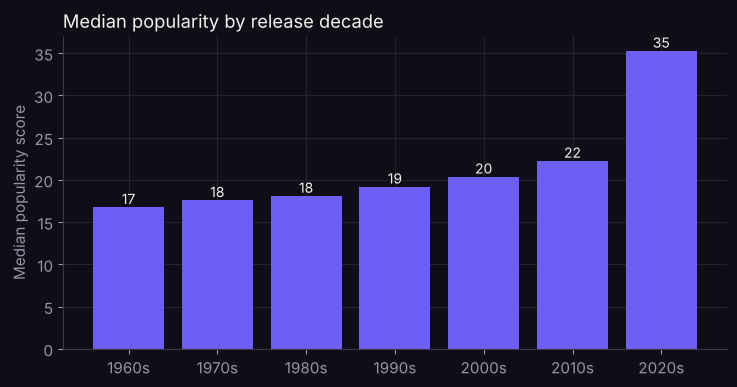

In [5]:
fig, ax = plt.subplots(figsize=(7.5,4))
ax.bar(dec.index.astype(str)+'s', dec['median'], color=A3)
for i,(d,r) in enumerate(dec.iterrows()): ax.text(i, r['median']+0.4, f"{r['median']:.0f}", ha='center', color=FG, fontsize=10)
ax.set_ylabel('Median popularity score'); ax.set_title('Median popularity by release decade', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/01_popularity_by_decade.png'); plt.show()

## 4. Rating: are better-rated films more popular?

In [6]:
rho_r, p_r = stats.spearmanr(rated['Vote_Average'], rated['Popularity'])
rho_v, p_v = stats.spearmanr(rated['Vote_Count'], rated['Popularity'])
print(f'Rating vs popularity (50+ votes): rho={rho_r:.2f}, p={p_r:.2g}')
print(f'Vote count vs popularity (50+ votes): rho={rho_v:.2f}, p={p_v:.2g}')
print(rated['Vote_Average'].describe().round(2))

Rating vs popularity (50+ votes): rho=0.13, p=1.6e-36
Vote count vs popularity (50+ votes): rho=0.40, p=0
count    8796.00
mean        6.56
std         0.86
min         1.80
25%         6.00
50%         6.60
75%         7.20
max         9.20
Name: Vote_Average, dtype: float64


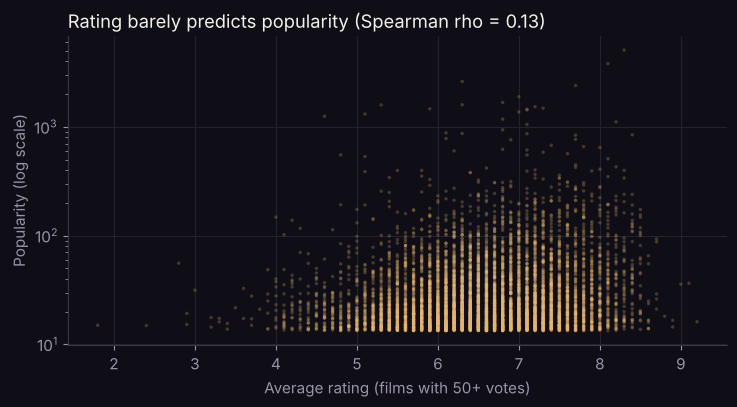

In [7]:
fig, ax = plt.subplots(figsize=(7.5,4.2))
ax.scatter(rated['Vote_Average'], rated['Popularity'], s=6, alpha=0.25, color=A2, edgecolor='none')
ax.set_yscale('log'); ax.set_xlabel('Average rating (films with 50+ votes)'); ax.set_ylabel('Popularity (log scale)')
ax.set_title(f'Rating barely predicts popularity (Spearman rho = {rho_r:.2f})', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/02_rating_vs_popularity.png'); plt.show()

## 5. Genre: which genres are common, popular and well rated?

In [8]:
g = df.explode('genres').rename(columns={'genres':'genre'})
g = g[g['genre'].notna() & (g['genre']!='')]
gs = g.groupby('genre').agg(films=('Title','size'), median_pop=('Popularity','median'))
gs['share_of_films'] = gs['films']/len(df)
gr = g[g['Vote_Count']>=50].groupby('genre')['Vote_Average'].median().rename('median_rating')
gs = gs.join(gr).sort_values('films', ascending=False)
print(gs.round(2))
h, p_g = stats.kruskal(*[x['Popularity'] for _, x in g.groupby('genre')])
print(f'Kruskal-Wallis, popularity across genres: H={h:.0f}, p={p_g:.2g}')

                 films  median_pop  share_of_films  median_rating
genre                                                            
Drama             3744       19.11            0.38            6.9
Comedy            3031       20.56            0.31            6.5
Action            2686       24.52            0.27            6.5
Thriller          2488       21.24            0.25            6.3
Adventure         1853       25.51            0.19            6.6
Romance           1476       19.33            0.15            6.7
Horror            1470       21.81            0.15            6.0
Animation         1438       27.43            0.15            7.0
Family            1414       24.94            0.14            6.7
Fantasy           1308       26.00            0.13            6.7
Science Fiction   1273       24.70            0.13            6.4
Crime             1242       19.94            0.13            6.6
Mystery            773       20.96            0.08            6.5
History   

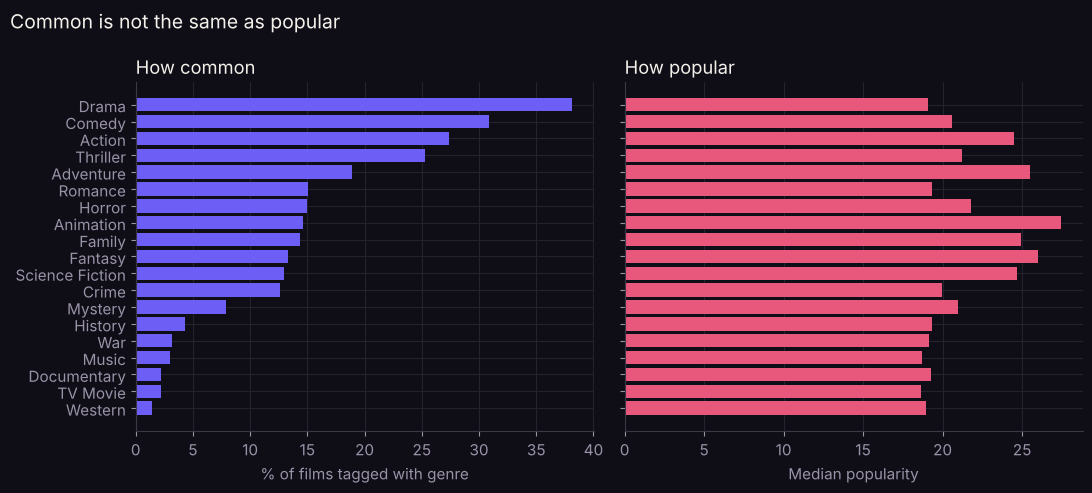

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,5), sharey=True)
order = gs.sort_values('films').index
axes[0].barh(order, gs.loc[order,'share_of_films']*100, color=A3); axes[0].set_xlabel('% of films tagged with genre')
axes[0].set_title('How common', loc='left', color=FG)
axes[1].barh(order, gs.loc[order,'median_pop'], color=A1); axes[1].set_xlabel('Median popularity')
axes[1].set_title('How popular', loc='left', color=FG)
fig.suptitle('Common is not the same as popular', x=0.01, ha='left', color=FG, fontsize=14)
fig.tight_layout(); fig.savefig('figures/03_genre_common_vs_popular.png'); plt.show()

## 6. Putting it together: what explains popularity?

In [10]:
main = gs.index[gs['films']>=300].tolist()
X = rated.copy()
for gname in main: X['g_'+gname.replace(' ','_')] = X['genres'].apply(lambda l: gname in l).astype(int)
X['log_votes'] = np.log10(X['Vote_Count']); X['years_old'] = X['year'].max() - X['year']
gterms = ' + '.join('g_'+x.replace(' ','_') for x in main)
models = {
  'Genre only': f'log_pop ~ {gterms}',
  'Recency only': 'log_pop ~ years_old',
  'Rating only': 'log_pop ~ Vote_Average',
  'Vote count only': 'log_pop ~ log_votes',
  'All together': f'log_pop ~ {gterms} + years_old + Vote_Average + log_votes'}
fits = {k: smf.ols(f, data=X).fit() for k,f in models.items()}
r2 = pd.Series({k: m.rsquared for k,m in fits.items()}).rename('R-squared')
print(r2.round(3))
full = fits['All together']
print(full.params[['years_old','Vote_Average','log_votes']].round(3))
print('Popularity multiplier per extra year of age:', round(10**full.params['years_old'],3))
print('Popularity multiplier per 10x more votes:', round(10**full.params['log_votes'],2))

Genre only         0.072
Recency only       0.069
Rating only        0.024
Vote count only    0.136
All together       0.298
Name: R-squared, dtype: float64
years_old      -0.005
Vote_Average    0.046
log_votes       0.182
dtype: float64
Popularity multiplier per extra year of age: 0.988
Popularity multiplier per 10x more votes: 1.52


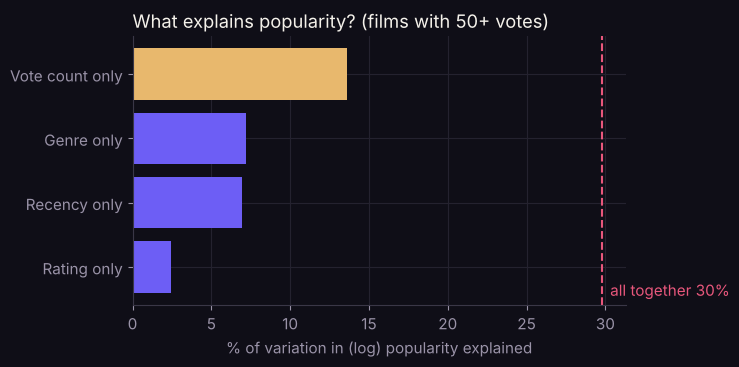

In [11]:
fig, ax = plt.subplots(figsize=(7.5,3.8))
r = r2.drop('All together').sort_values()
ax.barh(r.index, r.values*100, color=[A2 if 'Vote' in i else A3 for i in r.index])
ax.axvline(r2['All together']*100, color=A1, ls='--', lw=1.5); ax.text(r2['All together']*100+0.5, -0.45, f"all together {r2['All together']:.0%}", color=A1)
ax.set_xlabel('% of variation in (log) popularity explained')
ax.set_title('What explains popularity? (films with 50+ votes)', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/04_what_explains_popularity.png'); plt.show()

## 7. Summary

See the README for the written findings. The numbers above are the source; nothing in the README is typed in by hand without coming from these outputs.

**Limitations.** TMDB popularity reflects current attention when the data was collected, so it rewards films that are new or trending at that moment. Vote count partly *is* popularity, so its strong link is close to circular. The dataset is a list of already-popular films, not a random sample, so the results don't describe all films. Correlation is not causation.